In [10]:
import sys
sys.path.append("..")
from src.io_utils import load_data
df = load_data("../data/health_study_dataset.csv")

122.68488970435745
0.5360255996690454


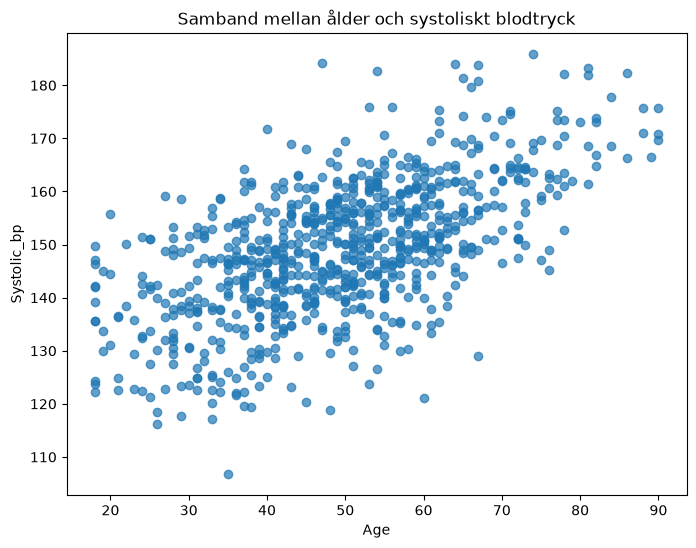

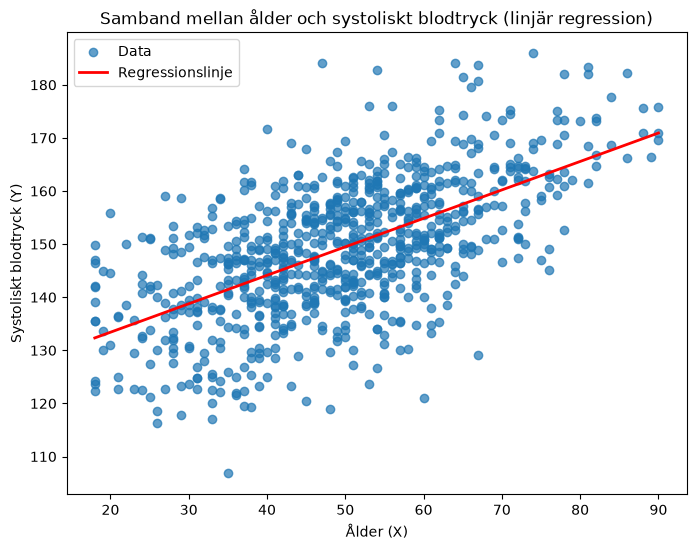

In [11]:
# DENNA MODUL INNEHÅLLER..

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
np.random.seed(42)

# En enkel linjär regression för att förutsäga blodtryck från ålder

def linear_regression(df):
    # 1. beräkna intercept och lutning
    X = df["age"].values # hämtar värdena från "age" och omvandlar dem till en np-array
    Y = df["systolic_bp"].values  # hämtar värdena från "systolic_bp" och omvandlar dem till en np-array

    # SCATTERPLOTT FÖR JÄMFÖRELSE..
    plt.figure(figsize=(8, 6))
    plt.scatter(X, Y, alpha=0.7, label="Data")
    plt.title("Samband mellan ålder och systoliskt blodtryck")
    plt.xlabel("Age")
    plt.ylabel("Systolic_bp")

    # 1.1 bygg upp designmatrisen (design_matrix): [1, x]
    ones_column = np.ones_like(X) # skapar en np array fylld med ettor, med samma form och storlek som X
    design_matrix = np.column_stack([ones_column, X]) # np.column_stack() staplar ihop flera arrayer som kolumner bredvid varandra
    transposed_design = design_matrix.T # transponerar design_matrix: rader blir kolumner
    # [1, 2],       [1, 1, 1]
    # [1, 5],  -->  [2, 5, 8]
    # [1, 8]]
    gram_matrix = transposed_design @ design_matrix # multiplicerar transponerade designmatrisen med originalmatrisen (X.T @ X)
    # [1, 1, 1]     [1, 2]     [3, 15]
    # [2, 5, 8]   @ [1, 5]  =  [15, 93]
    #               [1, 8]
    design_response = transposed_design @ Y # multiplicerar transponerade designmatrisen (X.T) med Y (systolic_bp)
    # summerar produkterna för att skapa en vektor som används vid beräkning av regressionsmodellens koefficienter
    beta_hat_vector = np.linalg.inv(gram_matrix) @ design_response # centrala beräkningen där vi faktiskt räknar fram regressionsmodellens koefficienter (intercept och lutning)
    # np.linalg.inv(gram_matrix) beräknar inversen av gram_matrix (X.T @ X)
    # @ multiplicerar inversen med design_response (X.T @ y)
    # Resultatet blir regressionsmodellens två koefficienter: intercept och lutning

    intercept_hat = float(beta_hat_vector[0]) # Hämtar det första värdet (index 0), alltså interceptet (Y när X = 0)
    slope_hat = float(beta_hat_vector[1]) # Hämtar det andra värdet (index 1), alltså lutningen (k)

    print(intercept_hat) # modellens intercept: beräknat Y-värde när X = 0)
    print(slope_hat)     # modellens lutning: hur mycket blodtrycket (Y) ökar med åldern(X)

    # 2. använd intercept och lutning för att se vad regressionsmodellen förutspår
    # jämför sedan förutsägelserna med våra riktiga datapunkter
    
    Y_hat_values = intercept_hat + slope_hat * X # skattar y-värden vid varje x
    residual_values = Y - Y_hat_values # jämför modellens skattningar med verkligheten

    # 3. ta fram figur
    plt.figure(figsize=(8, 6))
    plt.scatter(X, Y, alpha=0.7, label="Data")

    grid_X = np.linspace(18, 90, 200) # skapar 200 nya, jämnt fördelade åldersvärden för att rita en jämn regressionslinje
    # 18 och 90 är datasetets min- och maxåldrar
    # behöver inte använda datasetets alla 800 åldersvärden för att rita linjen.
    # Regressionslinjens lutning och intercept har däremot redan beräknats utifrån 
    # hela datasetet med 800 rader.
                                      
    grid_Y_manual = intercept_hat + slope_hat * grid_X
    # Räknar ut vilket Y-värde regressionslinjen har vid vart och ett av X-värdena
    # Använder interceptet och lutningen som vi räknade fram tidigare
 
    # 3.1 ta fram linje
    plt.plot(grid_X, grid_Y_manual, color="red", linewidth=2, label="Regressionslinje")
    plt.xlabel("Ålder (X)")
    plt.ylabel("Systoliskt blodtryck (Y)")
    plt.title("Samband mellan ålder och systoliskt blodtryck (linjär regression)")
    plt.legend()
    plt.show()            

resultat = linear_regression(df)
resultat


**1. Scatterplotet (spridningsdiagram) hjälper oss att undersöka:**
- Verkar blodtrycket öka med åldern?
- Finns det något samband?
- Hur mycket varierar blodtrycket mellan personer i samma ålder?
- Finns det några avvikande värden?
- OBS: scatterplotet räknar inte ut någon modell. Det visar bara våra observationer.

**2. Linjär regression – beräkna ett samband**
- Nu har vi lagt till en röd linje i diagrammet. Det är en regressionslinje som representerar den linje som bäst sammanfattar det linjära sambandet mellan ålder och blodtryck enligt minsta kvadratmetoden.
- Med den kan vi exempelvis uppskatta: vilket systoliskt blodtryck modellen förväntar sig vid en viss ålder.
- Vår linjära regression kan uppskatta blodtrycket även vid åldrar där vi saknar observationer, eftersom modellen utgår från den övergripande trenden i hela datasetet

**3. Men var kommer signifikans in?**
Här är en viktig skillnad:
- Linjär regression: Vi undersöker och modellerar sambandet mellan två variabler.
- Signifikansanalys: Vi kan undersöka om det finns statistiskt stöd för att sambandet skiljer sig från noll i populationen.
- Vi vill undersöka om lutningen i regressionslinjen är tillräckligt tydlig för att det ska vara osannolikt att den uppstått enbart på grund av slumpmässig variation




#### - Nollhypotes (H₀): Det finns inget linjärt samband mellan ålder och blodtryck (lutningen är 0)
#### - Alternativ hypotes (H₁): Det finns ett linjärt samband (lutningen skiljer sig från 0)

In [ ]:
# Beräkna korrelation med Numpy

import numpy as np

X = df["age"].values # hämtar värdena från "age" och omvandlar dem till en np-array
Y = df["systolic_bp"].values  # hämtar värdena från "systolic_bp" och omvandlar dem till en np-array

r = np.corrcoef(X, Y) # beräknas korrelationsmatris
print(f"r = {r[0, 1]}") # Hämtar korrelationen mellan X och Y

# Detta gav: r = 0.60757847098565

# TOLKNING: Korrelationen mellan ålder och systoliskt blodtryck är 0,607
# vilket indikerar ett positivt samband som kan bedömas som måttligt till starkt,
# beroende på vilket forskningsområde och vilka tumregler som används

r = 0.60757847098565


#### Källor:

- Korrelationsanalys: https://realpython.com/numpy-scipy-pandas-correlation-python/#example-numpy-correlation-calculation

- PCA-analys: Ryan # Matt Data Science, PCA Analysis in Python Explained (Scikit - Learn) https://www.youtube.com/watch?v=6uwa9EkUqpg

### Utökad analys och visualisering
- Lägg till minst en ny analys eller graf som ger en djupare förståelse (t.ex. relationen mellan blodtryck och ålder, eller sjukdomsförekomst per kön).

## PCA (Principal Component Analysis)

**Vi har dessa variabler i ditt hälsodataset:**

- Ålder(age)
- Vikt (weight)
- Längd (height)
- Blodtryck (systolic_bp)
- Kolesterol (cholesterol)
- Rökare (smoker (yes/no))
- Sjukdom (disease (1/0))

**PCA undersöker om flera variabler tenderar att förändras tillsammans**

t.ex:
- Hänger högre vikt ihop med högre blodtryck?
- Hänger högre ålder ihop med högre kolesterol?
- Finns det ett större gemensamt mönster mellan flera av dessa variabler?

In [14]:
%pip install skicit-learn

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement skicit-learn (from versions: none)

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for skicit-learn


In [ ]:
# pca tar bort oviktiga features..
import pandas as pd
import numpy as np
df = load_data("../data/health_study_dataset.csv")

df.drop("id", axis=1, inplace=True) # ta bort ID-kolumnen
display(df)

X = df.iloc[:, :8] # alla kolumner utom "disease"

display(X)

from sklearn.model_selection import train_test_split

# train_test_split delar upp din data i två delar så att du kan träna en 
# modell på en del och testa hur bra den fungerar på data den inte tränat på

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,  # 20 % av datan används för testning, 80 % för träning
    random_state=21 # Gör att uppdelningen blir likadan varje gång du kör koden
    )

C:\Users\Imad\AppData\Local\Temp\ipykernel_20372\1009929282.py:6: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop("id", axis=1, inplace=True) # ta bort ID-kolumnen


,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,57,F,168.9,65.8,141.8,4.58,No,0
1,47,M,180.4,95.9,144.8,5.18,Yes,0
2,59,F,169.9,82.2,151.7,6.16,No,0
3,72,M,157.7,93.1,151.0,6.63,No,0
4,46,M,192.6,104.1,144.1,5.21,No,0
...,...,...,...,...,...,...,...,...
795,65,M,177.2,73.6,174.3,4.31,Yes,0
796,49,M,177.4,86.1,150.6,5.40,No,0
797,60,F,175.0,49.7,146.5,5.57,No,0
798,50,F,172.6,55.3,155.0,3.58,No,0


,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,57,F,168.9,65.8,141.8,4.58,No,0
1,47,M,180.4,95.9,144.8,5.18,Yes,0
2,59,F,169.9,82.2,151.7,6.16,No,0
3,72,M,157.7,93.1,151.0,6.63,No,0
4,46,M,192.6,104.1,144.1,5.21,No,0
...,...,...,...,...,...,...,...,...
795,65,M,177.2,73.6,174.3,4.31,Yes,0
796,49,M,177.4,86.1,150.6,5.40,No,0
797,60,F,175.0,49.7,146.5,5.57,No,0
798,50,F,172.6,55.3,155.0,3.58,No,0


NameError: name 'y' is not defined